# Modeling and seeing what phrases and words that distinctibly identify the varieties

In [36]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sentence_transformers import SentenceTransformer

df = pd.read_pickle("processed_reviews.pkl")
df = df[df["variety"].notna()].reset_index(drop=True)
print(f"Shape: {df.shape}")
print("-"*1000)
print(df.info())

Shape: (169612, 31)
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [37]:
variety_counts = df["variety"].value_counts()

for t in [50, 100, 150, 300, 500, 1000]:
    keep = variety_counts[variety_counts >= t]
    print(f">= {t:>5}: {len(keep):>3} varieties | {keep.sum() / len(df):.1%} of reviews")


>=    50: 149 varieties | 96.9% of reviews
>=   100:  99 varieties | 94.8% of reviews
>=   150:  81 varieties | 93.5% of reviews
>=   300:  54 varieties | 90.0% of reviews
>=   500:  43 varieties | 87.4% of reviews
>=  1000:  34 varieties | 83.5% of reviews


In [38]:
grape_counts = df.loc[df["in_target"], "grape"].value_counts()


bucket_edges = [500, 1000, 2000, 5000, np.inf] # every target grape has 500+ reviews
bucket_labels = ["500-999", "1000-1999", "2000-4999", "5000+"]

grape_bucket = pd.cut(grape_counts, bins=bucket_edges, labels=bucket_labels, right=False) # creating the bucketize maping/ schema for the grape

df["bucket"] = df["grape"].map(grape_bucket) # bucket by grape (mapping by variety missed synonyms like Shiraz, Pinot Grigio)

In [39]:
bucket_summary = (df.groupby("bucket", observed=True)
                    .agg(varieties=("variety", "nunique"),
                         reviews=("variety", "size"))
                    .assign(pct_reviews=lambda d: (100 * d["reviews"] / d["reviews"].sum()).round(1)))
bucket_summary

,varieties,reviews,pct_reviews
bucket,,,
500-999,14,4914,4.3
1000-1999,16,11819,10.4
2000-4999,23,29283,25.8
5000+,15,67363,59.4


In [40]:
EMB_PATH = Path("embeddings_minilm_masked.npy")
encoder = SentenceTransformer("all-MiniLM-L6-v2") # popular embedding model used for comparing similar sentences

if EMB_PATH.exists():
    embeddings = np.load(EMB_PATH)
else:
    embeddings = encoder.encode(df["description_masked"].tolist(), batch_size=256, normalize_embeddings=True, show_progress_bar=True)
    np.save(EMB_PATH, embeddings)

print(embeddings.shape)

(169612, 384)


# Prototype per variety

In [41]:
is_train = (df["split"] == "train").to_numpy()
named = df["in_target"].to_numpy()

train_emb = embeddings[is_train & named] # grabs all trained data along with all varieties that aren't other
train_labels = df.loc[is_train & named, "grape"].to_numpy() # grabs the traning labels of ever training and variety label. 

global_mean = embeddings[is_train].mean(axis=0)
centered = train_emb - global_mean # calculates the centroid to be ready for cosine similarity

prototypes = pd.DataFrame(centered).groupby(train_labels).mean() # all centered or centroid of each vector is grouped with their label
proto = prototypes.to_numpy() # turned into a matrix or numpy
proto = proto / np.linalg.norm(proto, axis=1, keepdims=True) # Using L2 normalizes each prototype to unit length


# proto @ prot.T is dot product
sim = (pd.DataFrame(proto @ proto.T, index=prototypes.index, columns=prototypes.index)
         .rename_axis(index="variety_a", columns="variety_b")) # calculates the similarities 
sim.index.name, sim.columns.name = "variety_a", "variety_b" # for later reference


# Visualy seeing which varieites are simlar to each other

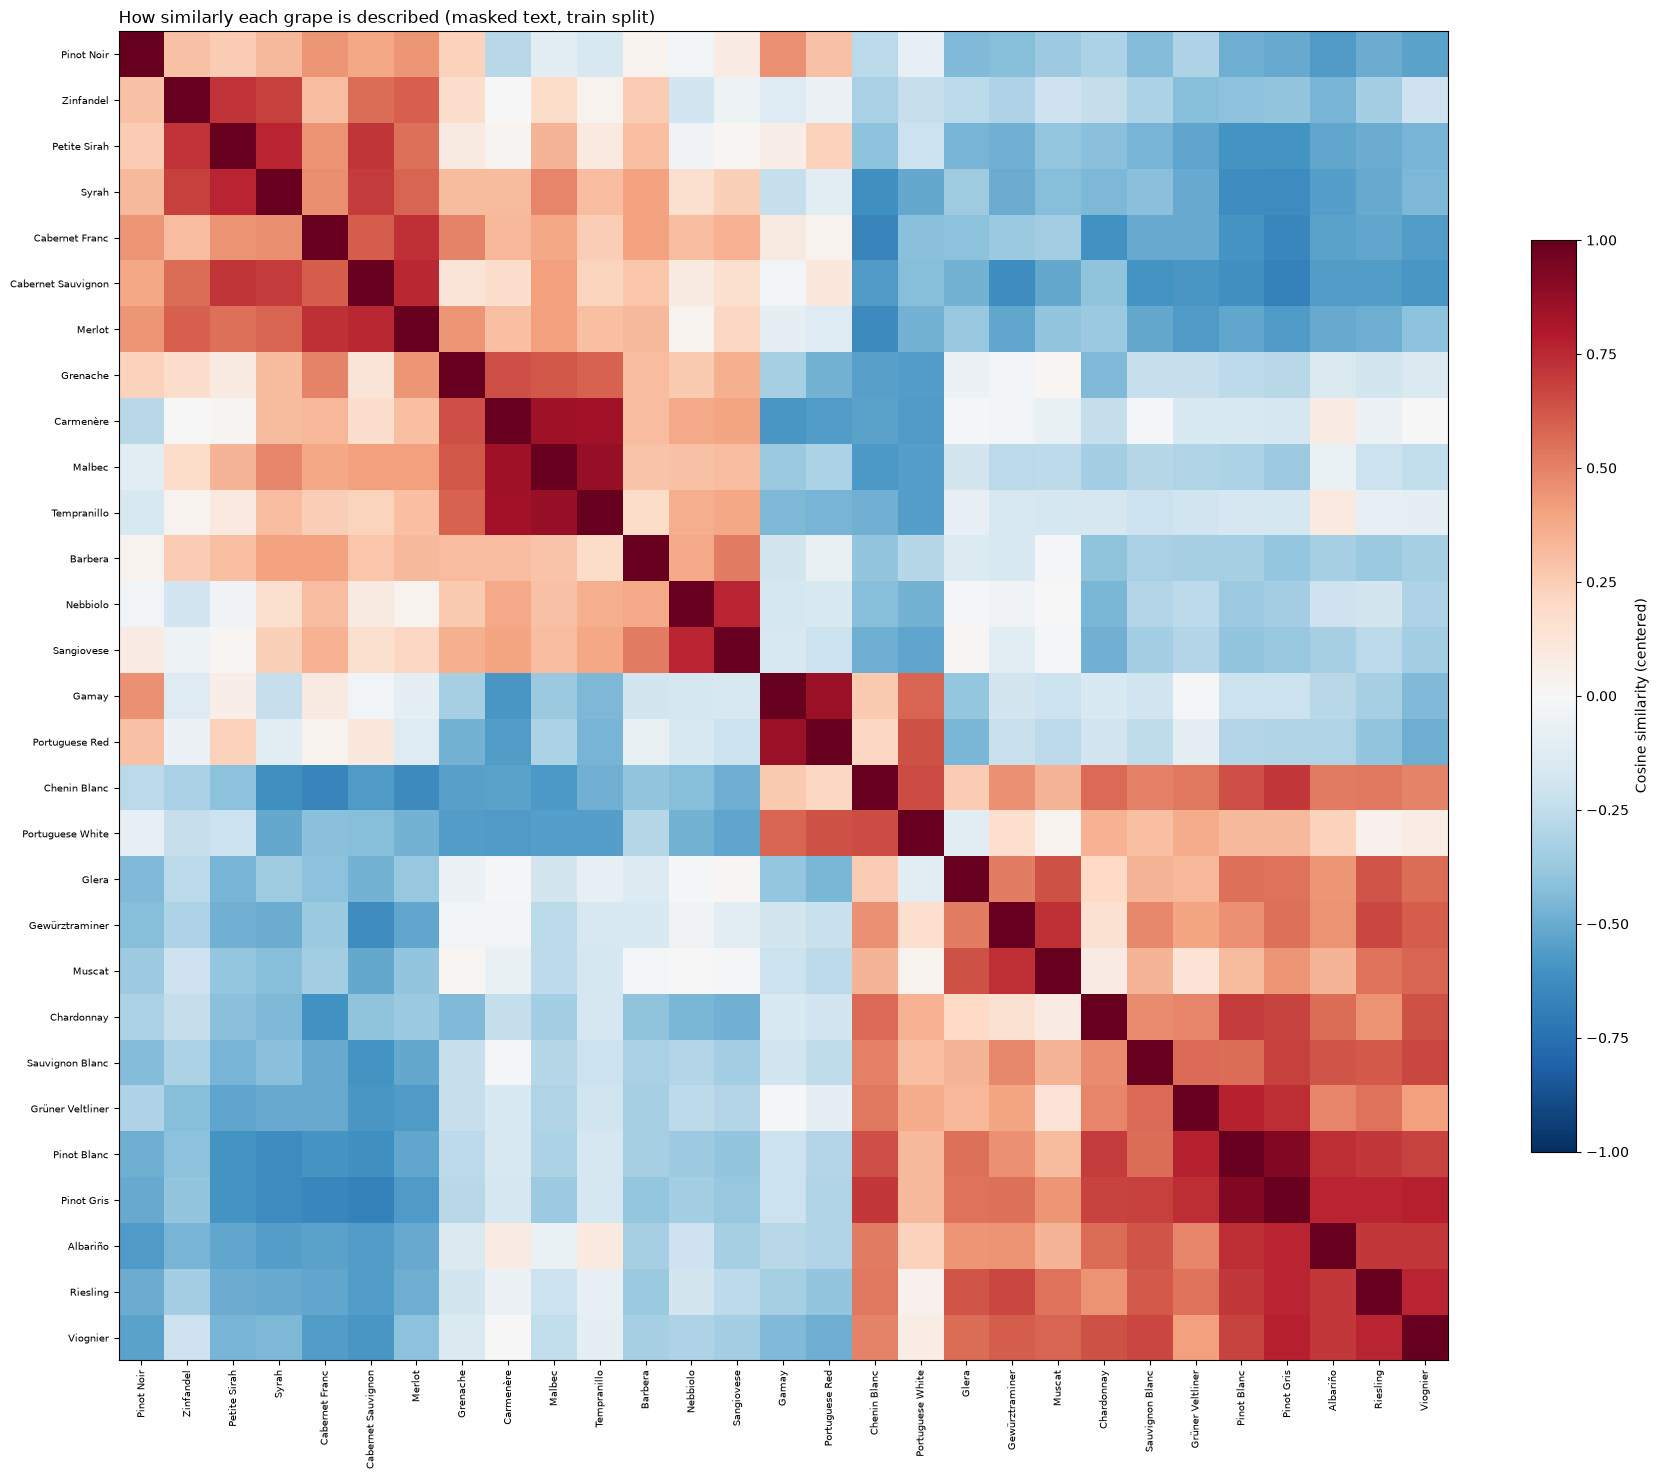

In [82]:
dist = np.clip(1 - sim.to_numpy(), 0, None)
np.fill_diagonal(dist, 0)
order = leaves_list(linkage(squareform(dist, checks=False), method="average"))
sim_ordered = sim.iloc[order, order]

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(sim_ordered, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(sim_ordered)), sim_ordered.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(sim_ordered)), sim_ordered.index, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.6, label="Cosine similarity (centered)")
ax.set_title("How similarly each grape is described (masked text, train split)", loc="left")
plt.tight_layout()
plt.show()


In [81]:
upper = np.triu(np.ones(sim.shape, dtype=bool), k=1)
pairs = (sim.where(upper).stack().dropna().rename("cosine").reset_index()
            .rename(columns={"variety_a": "grape_a", "variety_b": "grape_b"}))
pairs["bucket_a"] = pairs["grape_a"].map(grape_bucket)
pairs["bucket_b"] = pairs["grape_b"].map(grape_bucket)

pairs = pairs.sort_values("cosine", ascending=False).reset_index(drop=True)
pairs.to_csv("grape_cosine_pairs.csv", index=False, encoding="utf-8-sig")

with pd.option_context("display.max_rows", 60):
    print("Most similar grape pairs:")
    display(pairs.head(25).round(3))
    print("Least similar grape pairs:")
    display(pairs.tail(10).iloc[::-1].round(3))


Most similar grape pairs:


,grape_a,grape_b,cosine,bucket_a,bucket_b
0,Pinot Blanc,Pinot Gris,0.928,500-999,2000-4999
1,Malbec,Tempranillo,0.870,2000-4999,2000-4999
2,Gamay,Portuguese Red,0.862,1000-1999,2000-4999
3,Carmenère,Malbec,0.845,500-999,2000-4999
4,Carmenère,Tempranillo,0.839,500-999,2000-4999
5,Pinot Gris,Viognier,0.777,2000-4999,1000-1999
6,Grüner Veltliner,Pinot Blanc,0.771,1000-1999,500-999
7,Pinot Gris,Riesling,0.765,2000-4999,5000+
8,Riesling,Viognier,0.764,5000+,1000-1999
9,Albariño,Pinot Gris,0.762,500-999,2000-4999


Least similar grape pairs:


,grape_a,grape_b,cosine,bucket_a,bucket_b
405,Cabernet Sauvignon,Pinot Gris,-0.678,5000+,2000-4999
404,Cabernet Franc,Chenin Blanc,-0.664,1000-1999,500-999
403,Cabernet Franc,Pinot Gris,-0.652,1000-1999,2000-4999
402,Chenin Blanc,Merlot,-0.637,500-999,2000-4999
401,Pinot Gris,Syrah,-0.628,2000-4999,5000+
400,Cabernet Sauvignon,Gewürztraminer,-0.621,5000+,1000-1999
399,Pinot Blanc,Syrah,-0.621,500-999,5000+
398,Cabernet Sauvignon,Pinot Blanc,-0.616,5000+,500-999
397,Chenin Blanc,Syrah,-0.612,500-999,5000+
396,Cabernet Franc,Chardonnay,-0.609,1000-1999,5000+


# Analysis
The heatmap is a great way for us to narrow down our analysis. Many variety types of wine share common descriptions. For example, Temparanillo and Tempranillo Blend have similar descriptions because they likely have simlar if not the same ingredients used in both varieties of wine. Explains why the cosine similarity is high. This is can be commonly seen with wine varieties that either have similar names with one another. 

Examples of wines that have different names but have a high cosine similarity are Garnacha and Monastrell and Albarino and Verdejo. They boast a 0.9254 and 0.924600 cosine similarity score respectively. This sets up our analysis later to further investigate what words and phrases make these varieties taste alike, and what makes the different. 

In [44]:
from sklearn.preprocessing import LabelEncoder

model_df = df[df["in_target"]]
model_df = model_df[["review_id", "variety", "grape", "bucket", "split", "country", "province",
                     "taster_name", "description", "description_masked"]].copy()


model_df["emb_row"] = model_df.index
model_df = model_df.reset_index(drop=True)

label_encoder = LabelEncoder().fit(model_df["grape"])
model_df["y"] = label_encoder.transform(model_df["grape"])
n_classes = len(label_encoder.classes_)

print(f"{len(model_df)} reviews | {n_classes} classes")


113379 reviews | 29 classes


In [45]:
split_counts = pd.crosstab(model_df["grape"], model_df["split"])[["train", "val", "test"]]
split_counts["val_pct"] = (100 * split_counts["val"] / split_counts.sum(axis=1)).round(1)

print("Fewest reviews in any class per split:")
print(split_counts[["train", "val", "test"]].min())
split_counts.sort_values("train").head(10)


Fewest reviews in any class per split:
split
train    548
val      117
test     118
dtype: int64


split,train,val,test,val_pct
grape,,,,
Muscat,548,117,118,14.9
Albariño,553,118,119,14.9
Pinot Blanc,554,119,118,15.0
Carmenère,559,120,120,15.0
Chenin Blanc,566,121,122,15.0
Barbera,659,141,142,15.0
Petite Sirah,707,152,151,15.0
Gamay,775,166,166,15.0
Gewürztraminer,880,189,188,15.0


In [46]:
import re

def mentions_own_name(row):
    names = {row["variety"]}
    if isinstance(row["grape"], str):
        names.add(row["grape"])
    return any(re.search(rf"\b{re.escape(n)}\b", row["description"], flags=re.IGNORECASE)
               for n in names)

model_df["own_name_in_text"] = model_df.apply(mentions_own_name, axis=1)
model_df["any_name_in_text"] = model_df["description_masked"].str.contains("varietyname")

model_df.groupby("bucket", observed=True)[["own_name_in_text", "any_name_in_text"]].mean().round(3)


,own_name_in_text,any_name_in_text
bucket,,
500-999,0.339,0.387
1000-1999,0.204,0.340
2000-4999,0.228,0.313
5000+,0.239,0.397


In [47]:
raw_emb_path = Path("embeddings_minilm_raw.npy")

# Just incase the embeddings weren't saved
if raw_emb_path.exists():
    embeddings_raw = np.load(raw_emb_path)
else:
    embeddings_raw = encoder.encode(df["description"].tolist(), batch_size=256,
                                    normalize_embeddings=True, show_progress_bar=True)
    np.save(raw_emb_path, embeddings_raw)

emb_raw = embeddings_raw[model_df["emb_row"].to_numpy()]
emb_masked = embeddings[model_df["emb_row"].to_numpy()]
print(emb_raw.shape, emb_masked.shape)

(113379, 384) (113379, 384)


# Further understanding Comparing class-weighting schemes

In [48]:
train_counts = np.bincount(model_df.loc[model_df["split"] == "train", "y"], minlength=n_classes)

def class_weights(counts, scheme="sqrt", beta=0.999):
    if scheme == "inverse":
        w = 1/counts
    elif scheme == "sqrt":
        w = 1/np.sqrt(counts)
    elif scheme == "effective":
        w = (1 - beta) / (1 - beta ** counts)
    return w * counts.sum() / (w * counts).sum()

weight_table = pd.DataFrame({
    "train_reviews": train_counts,
    "inverse": class_weights(train_counts, "inverse"),
    "sqrt": class_weights(train_counts, "sqrt"),
    "effective": class_weights(train_counts, "effective"),
}, index=label_encoder.classes_).round(2)

weight_table.sort_values("train_reviews")

,train_reviews,inverse,sqrt,effective
Muscat,548,4.99,2.53,2.06
Albariño,553,4.95,2.52,2.05
Pinot Blanc,554,4.94,2.51,2.04
Carmenère,559,4.90,2.50,2.03
Chenin Blanc,566,4.84,2.49,2.01
Barbera,659,4.15,2.31,1.80
Petite Sirah,707,3.87,2.23,1.72
Gamay,775,3.53,2.13,1.61
Gewürztraminer,880,3.11,1.99,1.49
Grenache,882,3.10,1.99,1.48


In [49]:
model_df.to_pickle("model_data.pkl")
pd.Series(label_encoder.classes_, name="grape").to_csv("label_classes.csv", index=False)
weight_table.to_csv("class_weights.csv")

In [50]:
def get_split(name):
    part = model_df[model_df["split"] == name]
    rows = part["emb_row"].to_numpy()
    return part, embeddings_raw[rows], embeddings[rows], part["y"].to_numpy()

# Archite3cture of our Model Prototype 1:

```
                    ┌─ M1: TF-IDF (words + phrases) → Logistic Regression ─┐
review description ─┼─ M2: Doc2Vec embedding → LSTM (weighted CE / focal)   ─┼─→ combine probabilities → grape
                    └─ M3: MiniLM embedding → cosine to 29 prototypes     ─┘
```

| Model | Input | Method | Output |
|---|---|---|---|
| **M1** | TF-IDF (words + phrases) | Logistic Regression | Probability for each of the 29 grape classes  |
| **M2** | Doc2Vec embedding + word sequence | BiLSTM (RNN) utilizing Doc2Vec embeddings, weighted CE | Probability for each of the 29 grape classes |
| **M3** | MiniLM embedding | Cosine similarity to 29 grape prototypes | Probability for each of the 29 grape classes  |

The three probability outputs are **combined** (weighted average tuned on `val`) to predict the final **grape**.


In [51]:
import numpy as np
import pandas as pd
import torch
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, top_k_accuracy_score, log_loss

model_df = pd.read_pickle("model_data.pkl")
classes = pd.read_csv("label_classes.csv")["grape"].to_numpy()
weight_table = pd.read_csv("class_weights.csv", index_col=0)
embeddings_masked = np.load("embeddings_minilm_masked.npy")
embeddings_raw = np.load("embeddings_minilm_raw.npy")

n_classes = len(classes)
WEIGHT_SCHEME = "sqrt"
class_w = weight_table.loc[classes, WEIGHT_SCHEME].to_numpy()

print(f"{n_classes} classes | GPU available: {torch.cuda.is_available()}")


29 classes | GPU available: False


In [52]:
def get_split(name):
    part = model_df[model_df["split"] == name]
    rows = part["emb_row"].to_numpy()
    return part, embeddings_raw[rows], embeddings_masked[rows], part["y"].to_numpy()

train, train_raw, train_masked, y_train = get_split("train")
val, val_raw, val_masked, y_val = get_split("val")
test, test_raw, test_masked, y_test = get_split("test")

print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

train 79,363 | val 17,006 | test 17,010


# Evaluation Function for all models

In [53]:
results = []

def sub_f1(y, pred, mask): 
    return f1_score(y[mask], pred[mask], labels=np.unique(y[mask]), average="macro", zero_division=0)

def evaluate(name, part, proba, y): 
    pred = proba.argmax(axis=1)
    named = part["own_name_in_text"].to_numpy()

    row = {"model": name, 
           "macro_f1": f1_score(y, pred, average="macro"),
           "accuracy": accuracy_score(y, pred),
           "top3_acc": top_k_accuracy_score(y, proba, k=3, labels=np.arange(n_classes)),
           "f1_name_present": sub_f1(y, pred, named),
           "f1_name_abset": sub_f1(y, pred, ~named)
    }

    for bucket, idx in part.groupby("bucket", observed=True).indices.items():
        mask = np.zeros(len(part), dtype=bool)
        mask[idx] = True
        row[f"f1_{bucket}"] = sub_f1(y, pred, mask)

    results.append(row)
    return pd.Series(row)


# Model 1: TF-IDF --> Logistic Regression

In [54]:
train_text = pd.concat([train["description"], train["description_masked"]], ignore_index=True) # concat the both description and masked
y_train_m1 = np.concatenate([y_train, y_train]) # Combining two class training --> one for normal and masked

word_vec = TfidfVectorizer(ngram_range=(1, 3), min_df=5, sublinear_tf=True) # check back and modify to 1,2 later if it'll improve
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, sublinear_tf=True, max_features=300000)

X_train_m1 = hstack([word_vec.fit_transform(train_text), char_vec.fit_transform(train_text)]).tocsr()

def m1_features(text):
    return hstack([word_vec.transform(text), char_vec.transform(text)]).tocsr()

X_val_m1 = m1_features(val["description"])
X_test_m1 = m1_features(test["description"])
print(X_train_m1.shape)

(158726, 375362)


In [55]:
m1 = LogisticRegression(C=1.0, max_iter=1000)
m1.fit(X_train_m1, y_train_m1, sample_weight=class_w[y_train_m1])

proba_val_m1 = m1.predict_proba(X_val_m1) 
np.save("proba_val_m1.npy", proba_val_m1)
evaluate("M1: TF-IDF + LogReg", val, proba_val_m1, y_val)

model              M1: TF-IDF + LogReg
macro_f1                      0.646603
accuracy                      0.728272
top3_acc                       0.89392
f1_name_present               0.913372
f1_name_abset                 0.526821
f1_500-999                     0.62438
f1_1000-1999                  0.720438
f1_2000-4999                  0.751093
f1_5000+                      0.831885
dtype: object

In [56]:
import joblib

joblib.dump({"model": m1, "word_vec": word_vec, "char_vec": char_vec}, "m1_tfidf_logreg.joblib")

proba_test_m1 = m1.predict_proba(X_test_m1)
np.save("proba_test_m1.npy", proba_test_m1)



Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)



# Model 2: Doc2Vec + BiLSTM 

# Doc2Vec: 
Doc2Vec (Le & Mikolov, 2014, also called “Paragraph Vectors”) extends Word2Vec. Word2Vec learns a dense vector for each word by training a small neural network to predict words from their neighbors. Words used in similar contexts, like “doctor” and “physician”, end up with similar vectors.

**Two Variants** 
1. PV-DM (Distributed Memory). To predict the next word in a window, the model combines the surrounding word vectors with the document’s vector. The document vector acts as a memory of what the document is about, supplying context the local words don’t.
2. PV-DBOW (Distributed Bag of Words). The document vector alone is trained to predict words sampled from that document. It is simpler and faster, and often works as well or better.



In [57]:
import os
import re
import time
import pandas as pd
import numpy as np
from pathlib import Path
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

SEED = 67
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

def tokenize(text):
    return TOKEN_RE.findall(text.lower()) # tokenizeds and splits up all of the words 

train_tok_m2 = [tokenize(t) for t in pd.concat([train["description"], train["description_masked"]], ignore_index=True)] # tokenizes all of the words 
y_train_m2 = np.concatenate([y_train, y_train])
val_tok_m2 = [tokenize(t) for t in val["description"]]
test_tok_m2 = [tokenize(t) for t in test["description"]]

D2V_PATH = Path("m2_doc2vec.model")



# Just to make things easier this will save all tokenized words within description and masked. 
if D2V_PATH.exists():
    d2v = Doc2Vec.load(str(D2V_PATH)) 
else:
    tagged = [TaggedDocument(toks, [i]) for i, toks in enumerate(train_tok_m2)]
    d2v = Doc2Vec(vector_size=150, dm=0, dbow_words=1,
                  window=5, min_count=5, negative=5, sample=1e-4,
                  epochs=20, workers=os.cpu_count(), seed=SEED) # Doc2Vec 
    d2v.build_vocab(tagged)
    d2v.train(tagged, total_examples=len(tagged), epochs=d2v.epochs)
    d2v.save(str(D2V_PATH))

print(f"Doc2Vec vocab: {len(d2v.wv):,} words | vector size {d2v.vector_size}")


Doc2Vec vocab: 13,333 words | vector size 150


In [58]:
def infer_doc_vectors(token_lists, path):
    path = Path(path)
    if path.exists():
        return np.load(path)
    vecs = np.vstack([d2v.infer_vector(toks, epochs=d2v.epochs) for toks in token_lists]).astype(np.float32)
    np.save(path, vecs)
    return vecs

train_doc_m2 = infer_doc_vectors(train_tok_m2, "m2_docvec_train.npy")
val_doc = infer_doc_vectors(val_tok_m2, "m2_docvec_val.npy")
test_doc = infer_doc_vectors(test_tok_m2, "m2_docvec_test.npy")

# Stops here if old cached vectors (from a different target/split) were loaded by mistake.
# Compares against the token lists, since train_ids_m2 / val_ids are only built in the next cell.
assert len(train_doc_m2) == len(train_tok_m2) and len(val_doc) == len(val_tok_m2) and len(test_doc) == len(test_tok_m2), \
    "Doc2Vec vectors don't match the data: delete the m2_docvec_*.npy files and rerun"

# Standardizing the doc_m2 vectors
doc_mean, doc_std = train_doc_m2.mean(axis=0), train_doc_m2.std(axis=0) + 1e-6
train_doc_m2, val_doc, test_doc = [(v - doc_mean) / doc_std for v in (train_doc_m2, val_doc, test_doc)] 

print(train_doc_m2.shape, val_doc.shape, test_doc.shape)


(158726, 150) (17006, 150) (17010, 150)


In [59]:
# turns the tokenized words into numbers..... Neeed to do this for the RNN

MAX_LEN = 72
PAD, UNK = 0, 1

word_index = {w: i + 2 for i, w in enumerate(d2v.wv.index_to_key)}

emb_matrix = np.zeros((len(word_index) + 2, d2v.vector_size), dtype=np.float32)
emb_matrix[2:] = d2v.wv.vectors
emb_matrix[UNK] = d2v.wv.vectors.mean(axis=0)

def to_ids(token_lists):
    ids = np.zeros((len(token_lists), MAX_LEN), dtype=np.int64)
    lengths = np.zeros(len(token_lists), dtype=np.int64)
    for r, toks in enumerate(token_lists):
        seq = [word_index.get(w, UNK) for w in toks[:MAX_LEN]] or [UNK]
        ids[r, :len(seq)] = seq
        lengths[r] = len(seq)
    return ids, lengths

train_ids_m2, train_len_m2 = to_ids(train_tok_m2)
val_ids, val_len = to_ids(val_tok_m2)
test_ids, test_len = to_ids(test_tok_m2)
print(f"unknown-word rate in val: {(val_ids == UNK).sum() / val_len.sum():.2%}")


unknown-word rate in val: 0.72%


In [60]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def reverse_padded(x, lengths):
    pos = torch.arange(x.size(1), device=x.device)[None, :]
    rev = lengths[:, None] - 1 - pos
    rev = torch.where(rev >= 0, rev, pos)
    return x.gather(1, rev.unsqueeze(-1).expand_as(x))

class Doc2VecBiLSTM(nn.Module):
    def __init__(self, emb_matrix, doc_dim, n_classes, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=PAD)
        self.emb_drop = nn.Dropout(0.2)
        self.lstm_fw = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True)
        self.lstm_bw = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(4 * hidden + doc_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),
        )

    def forward(self, ids, lengths, doc_vec):
        x = self.emb_drop(self.emb(ids))
        out_fw, _ = self.lstm_fw(x)
        out_bw, _ = self.lstm_bw(reverse_padded(x, lengths))
        out = torch.cat([out_fw, reverse_padded(out_bw, lengths)], dim=2)

        mask = (torch.arange(out.size(1), device=out.device)[None, :] < lengths[:, None]).unsqueeze(-1)
        mean_pool = (out * mask).sum(dim=1) / lengths[:, None]
        max_pool = out.masked_fill(~mask, -1e4).max(dim=1).values
        return self.head(torch.cat([mean_pool, max_pool, doc_vec], dim=1))


In [61]:
def length_batches(lengths, batch_size, rng):
    order = np.argsort(lengths + rng.random(len(lengths)) * 6, kind="stable")
    chunks = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    rng.shuffle(chunks)
    return chunks

def to_tensors(ids, lengths, doc, idx, y=None):
    max_len = lengths[idx].max()
    out = (torch.from_numpy(ids[idx, :max_len]).to(device),
           torch.from_numpy(lengths[idx]).to(device),
           torch.from_numpy(doc[idx]).to(device))
    return out + (torch.from_numpy(y[idx]).to(device),) if y is not None else out

@torch.no_grad()
def predict_m2(model, ids, lengths, doc, batch_size=1024):
    model.eval()
    order = np.argsort(lengths, kind="stable")
    proba = np.zeros((len(lengths), n_classes), dtype=np.float32)
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        proba[idx] = torch.softmax(model(*to_tensors(ids, lengths, doc, idx)), dim=1).cpu().numpy()
    return proba


In [62]:
M2_PATH = Path("m2_doc2vec_bilstm.pt")
EPOCHS, PATIENCE, BATCH_SIZE = 12, 2, 256

torch.manual_seed(SEED)
model_m2 = Doc2VecBiLSTM(emb_matrix, d2v.vector_size, n_classes).to(device)

if M2_PATH.exists():
    model_m2.load_state_dict(torch.load(M2_PATH, map_location=device))
else:
    rng = np.random.default_rng(SEED)
    optimizer = torch.optim.AdamW(model_m2.parameters(), lr=2e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=0)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32, device=device))

    best_f1, best_state, epochs_without_gain = -1.0, None, 0
    for epoch in range(1, EPOCHS + 1):
        model_m2.train()
        start, running_loss, n_seen = time.time(), 0.0, 0
        for idx in length_batches(train_len_m2, BATCH_SIZE, rng):
            ids, lengths, doc, y = to_tensors(train_ids_m2, train_len_m2, train_doc_m2, idx, y_train_m2)
            optimizer.zero_grad()
            loss = loss_fn(model_m2(ids, lengths, doc), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model_m2.parameters(), 1.0)
            optimizer.step()
            running_loss += loss.item() * len(idx)
            n_seen += len(idx)

        val_f1 = f1_score(y_val, predict_m2(model_m2, val_ids, val_len, val_doc).argmax(axis=1), average="macro")
        scheduler.step(val_f1)
        print(f"epoch {epoch:>2} | train loss {running_loss / n_seen:.4f} | val macro F1 {val_f1:.4f} | {time.time() - start:.0f}s")

        if val_f1 > best_f1:
            best_f1, epochs_without_gain = val_f1, 0
            best_state = {k: v.detach().clone() for k, v in model_m2.state_dict().items()}
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= PATIENCE:
                print("Stopping early")
                break

    model_m2.load_state_dict(best_state)
    torch.save(best_state, M2_PATH)


epoch  1 | train loss 1.4236 | val macro F1 0.6273 | 90s
epoch  2 | train loss 1.0445 | val macro F1 0.6537 | 89s
epoch  3 | train loss 0.8567 | val macro F1 0.6449 | 97s
epoch  4 | train loss 0.6617 | val macro F1 0.6377 | 105s
Stopping early


In [63]:
proba_val_m2 = predict_m2(model_m2, val_ids, val_len, val_doc)
proba_test_m2 = predict_m2(model_m2, test_ids, test_len, test_doc)
np.save("proba_val_m2.npy", proba_val_m2)
np.save("proba_test_m2.npy", proba_test_m2)

evaluate("M2: Doc2Vec + BiLSTM", val, proba_val_m2, y_val)


model              M2: Doc2Vec + BiLSTM
macro_f1                        0.65365
accuracy                       0.728566
top3_acc                       0.888275
f1_name_present                0.979014
f1_name_abset                  0.517118
f1_500-999                     0.699345
f1_1000-1999                   0.766092
f1_2000-4999                   0.733199
f1_5000+                       0.834035
dtype: object

# Model 3: Cosine score --> probabilities of how likely a description is to a Variety type

In [64]:
"""
Example: 
length = √(2² + 1²) = √5 ≈ 2.2361
[2, −1] / 2.2361 = [0.8944, −0.4472]

score 0 = 0.8944 × 0.9487  +  (−0.4472) × (−0.3162)
        = 0.8485 + 0.1414
        ≈ 0.990

score 1 = 0.8944 × (−0.9487)  +  (−0.4472) × 0.3162
        ≈ −0.990
"""


def normalize(x):
    """
    length of [1.5, −0.5] = √(1.5² + 0.5²) = √2.5 ≈ 1.5811

    proto 0 = [1.5, −0.5] / 1.5811 = [ 0.9487, −0.3162]
    proto 1 = [−1.5, 0.5] / 1.5811 = [−0.9487,  0.3162]
    """
    return x / np.linalg.norm(x, axis=1, keepdims=True) # normalizing the data for scalability reasons
train_emb_m3 = np.vstack([train_raw, train_masked]) # vstack --->  combine both raw and masked in a vectorized format
y_train_m3 = np.concatenate([y_train, y_train]) 
center = train_emb_m3.mean(axis=0)

protos = normalize(np.vstack([(train_emb_m3[y_train_m3 == k] - center).mean(axis=0) # Stacks after averaging all class avg(characters - center)
                              for k in range(n_classes)]))

def m3_scores(emb):
    return normalize(emb - center) @ protos.T



In [65]:
def softmax(z): 
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e /e.sum(axis=1, keepdims=True)

val_score_m3 = m3_scores(val_raw)

temps = [0.01, 0.02, 0.03, 0.05, 0.1, 0.2]
losses = {T: log_loss(y_val, softmax(val_score_m3 / T), labels=np.arange(n_classes)) for T in temps}
best_T = min(losses, key=losses.get)
print(pd.Series(losses, name="val log-loss").round(4), "\nbest T:", best_T)

proba_val_m3 = softmax(val_score_m3 / best_T)
np.save("proba_val_m3.npy", proba_val_m3)
evaluate("M3: Cosine prototypes", val, proba_val_m3, y_val)

0.01    6.6745
0.02    4.9119
0.03    3.7618
0.05    2.6857
0.10    2.2121
0.20    2.4469
Name: val log-loss, dtype: float64 
best T: 0.1


model              M3: Cosine prototypes
macro_f1                        0.386506
accuracy                        0.438492
top3_acc                        0.594202
f1_name_present                 0.715768
f1_name_abset                   0.250337
f1_500-999                      0.553452
f1_1000-1999                    0.592062
f1_2000-4999                    0.551782
f1_5000+                        0.556972
dtype: object

# Final Model Structure

In [66]:
proba_test_m3 = softmax(m3_scores(test_raw) / best_T)
np.save("proba_test_m3.npy", proba_test_m3)

In [67]:
from itertools import product

val_probas = [proba_val_m1, proba_val_m2, proba_val_m3]
test_probas = [proba_test_m1, proba_test_m2, proba_test_m3]

grid = np.round(np.arange(0, 1.01, 0.1), 2)
search = []
for w1, w2 in product(grid, grid):
    w3 = round(1 - w1 - w2, 2)
    if w3 < 0:
        continue
    blend = w1 * val_probas[0] + w2 * val_probas[1] + w3 * val_probas[2]
    search.append({"w_m1": w1, "w_m2": w2, "w_m3": w3,
                   "val_macro_f1": f1_score(y_val, blend.argmax(axis=1), average="macro")})

search = pd.DataFrame(search).sort_values("val_macro_f1", ascending=False)
best_w = search.iloc[0][["w_m1", "w_m2", "w_m3"]].to_numpy()
print("best weights (M1, M2, M3):", best_w)
search.head(10)


best weights (M1, M2, M3): [0.6 0.4 0. ]


,w_m1,w_m2,w_m3,val_macro_f1
55,0.6,0.4,0.0,0.681704
54,0.6,0.3,0.1,0.680999
59,0.7,0.3,0.0,0.680611
49,0.5,0.4,0.1,0.680555
48,0.5,0.3,0.2,0.680206
50,0.5,0.5,0.0,0.678974
43,0.4,0.5,0.1,0.676498
42,0.4,0.4,0.2,0.675428
58,0.7,0.2,0.1,0.674978
53,0.6,0.2,0.2,0.674961


In [68]:
def blend(probas, w):
    return sum(wi * p for wi, p in zip(w, probas))

proba_val_ens = blend(val_probas, best_w)
proba_test_ens = blend(test_probas, best_w)
np.save("proba_test_ens.npy", proba_test_ens)

evaluate("Ensemble: M1+M2+M3", val, proba_val_ens, y_val)


model              Ensemble: M1+M2+M3
macro_f1                     0.681704
accuracy                      0.75097
top3_acc                     0.903622
f1_name_present              0.976726
f1_name_abset                 0.54804
f1_500-999                   0.694874
f1_1000-1999                 0.765407
f1_2000-4999                 0.756894
f1_5000+                     0.849062
dtype: object

# Overall Results

In [69]:
results = []
for name, proba in [("M1: TF-IDF + LogReg", proba_test_m1),
                    ("M2: Doc2Vec + BiLSTM", proba_test_m2),
                    ("M3: Cosine prototypes", proba_test_m3),
                    ("Ensemble: M1+M2+M3", proba_test_ens)]:
    evaluate(name, test, proba, y_test)

test_scores = pd.DataFrame(results).set_index("model")
test_scores.to_csv("test_scores.csv")
test_scores.round(3)

,macro_f1,accuracy,top3_acc,f1_name_present,f1_name_abset,f1_500-999,f1_1000-1999,f1_2000-4999,f1_5000+
model,,,,,,,,,
M1: TF-IDF + LogReg,0.642,0.728,0.890,0.909,0.523,0.631,0.698,0.746,0.836
M2: Doc2Vec + BiLSTM,0.647,0.726,0.884,0.980,0.512,0.687,0.746,0.744,0.828
M3: Cosine prototypes,0.377,0.430,0.590,0.717,0.247,0.523,0.589,0.546,0.548
Ensemble: M1+M2+M3,0.678,0.751,0.900,0.974,0.546,0.693,0.751,0.763,0.849


In [70]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix

MODEL_COLORS = {"M1": "#2a78d6", "M2": "#eb6834", "M3": "#1baf7a", "Ensemble": "#52514e"}
INK, INK_2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
STYLE = {
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
}

def color_of(name):
    return MODEL_COLORS[name.split(":")[0]]

test_scores = pd.read_csv("test_scores.csv", index_col="model")
test_probas = {
    "M1: TF-IDF + LogReg": np.load("proba_test_m1.npy"),
    "M2: Doc2Vec + BiLSTM": np.load("proba_test_m2.npy"),
    "M3: Cosine prototypes": np.load("proba_test_m3.npy"),
    "Ensemble: M1+M2+M3": np.load("proba_test_ens.npy"),
}


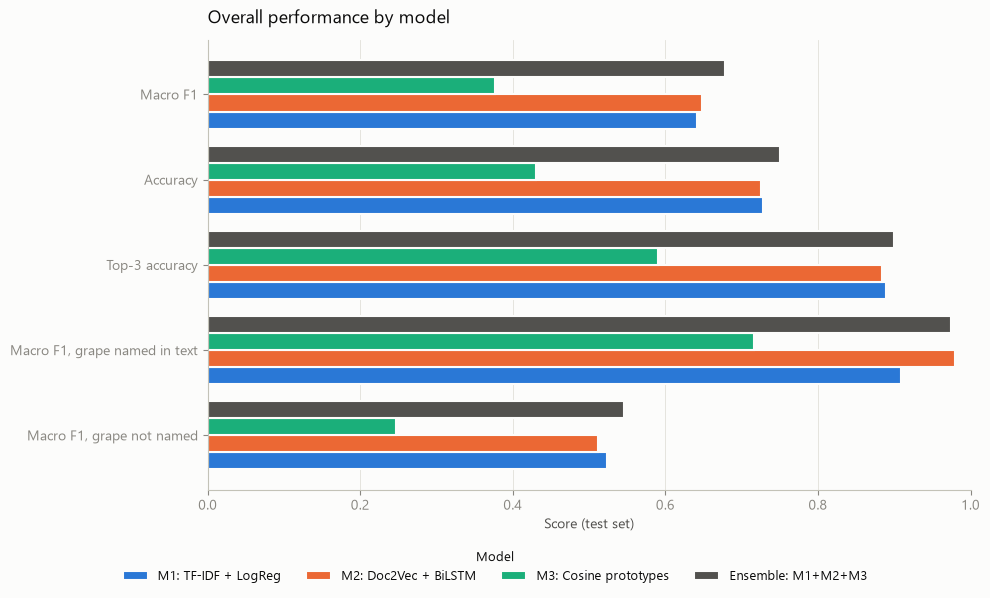

,macro_f1,accuracy,top3_acc,f1_name_present,f1_name_abset
model,,,,,
M1: TF-IDF + LogReg,0.642,0.728,0.890,0.909,0.523
M2: Doc2Vec + BiLSTM,0.647,0.726,0.884,0.980,0.512
M3: Cosine prototypes,0.377,0.430,0.590,0.717,0.247
Ensemble: M1+M2+M3,0.678,0.751,0.900,0.974,0.546


In [75]:
overall = {"macro_f1": "Macro F1", "accuracy": "Accuracy", "top3_acc": "Top-3 accuracy",
           "f1_name_present": "Macro F1, grape named in text", "f1_name_abset": "Macro F1, grape not named"}

names = list(test_scores.index)
n_models = len(names)
bar_h = 0.8 / n_models
y = np.arange(len(overall))

with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(10, 6))
    for k, name in enumerate(names):
        vals = test_scores.loc[name, list(overall)].astype(float)
        ax.barh(y + ((n_models - 1) / 2 - k) * bar_h, vals, height=bar_h, color=color_of(name),
                edgecolor=SURFACE, linewidth=1.5, label=name)
    ax.set_yticks(y, list(overall.values()))
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.set_xlabel("Score (test set)")
    ax.set_title("Overall performance by model", loc="left", fontsize=13, pad=12)
    fig.legend(*ax.get_legend_handles_labels(), title="Model", loc="lower center",
               bbox_to_anchor=(0.5, 0), ncol=n_models, fontsize=9, title_fontsize=9)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

display(test_scores[list(overall)].astype(float).round(3))


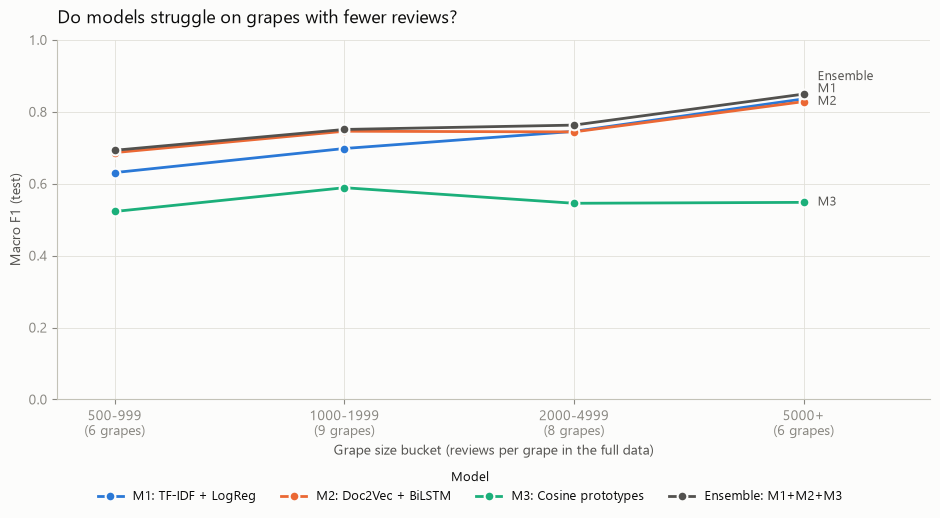

In [77]:
buckets = ["500-999", "1000-1999", "2000-4999", "5000+"]
grapes_per_bucket = model_df.groupby("bucket", observed=True)["grape"].nunique()
tick_labels = [f"{b}\n({grapes_per_bucket[b]} grapes)" for b in buckets]
x = np.arange(len(buckets))

def spread_labels(values, min_gap=0.035):
    """Nudges end-of-line label positions apart so they don't overlap; returns them in the original order."""
    order = np.argsort(values)
    placed = np.array(values, dtype=float)[order]
    for i in range(1, len(placed)):
        placed[i] = max(placed[i], placed[i - 1] + min_gap)
    out = np.empty_like(placed)
    out[order] = placed
    return out

with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    end_values = []
    for name, row in test_scores.iterrows():
        vals = row[[f"f1_{b}" for b in buckets]].astype(float).to_numpy()
        ax.plot(x, vals, color=color_of(name), marker="o", markersize=7,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
        end_values.append(vals[-1])

    for name, y_label in zip(test_scores.index, spread_labels(end_values)):
        ax.annotate(name.split(":")[0], xy=(x[-1], y_label), xytext=(10, 0),
                    textcoords="offset points", va="center", color=INK_2, fontsize=9)

    ax.set_xticks(x, tick_labels)
    ax.set_xlim(-0.25, len(buckets) - 1 + 0.55)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Grape size bucket (reviews per grape in the full data)")
    ax.set_ylabel("Macro F1 (test)")
    ax.set_title("Do models struggle on grapes with fewer reviews?", loc="left", fontsize=13, pad=12)
    fig.legend(*ax.get_legend_handles_labels(), title="Model", loc="lower center",
               bbox_to_anchor=(0.5, 0), ncol=len(test_scores), fontsize=9, title_fontsize=9)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()


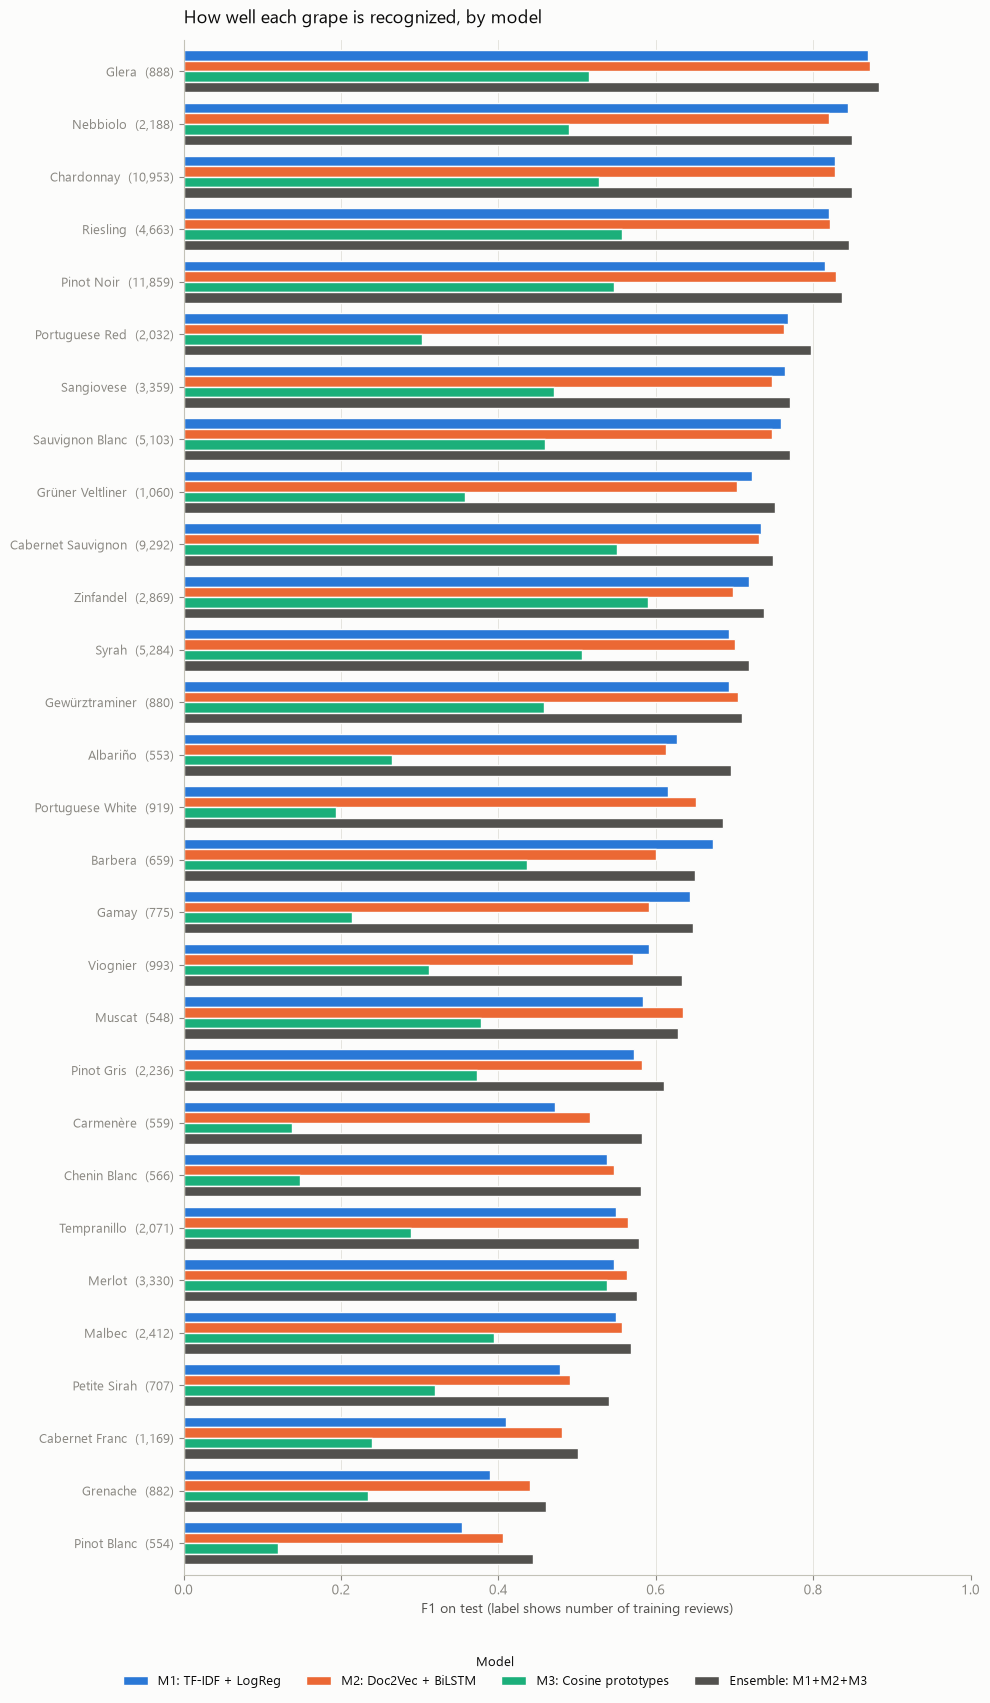

,M1: TF-IDF + LogReg,M2: Doc2Vec + BiLSTM,M3: Cosine prototypes,Ensemble: M1+M2+M3
Glera,0.870,0.872,0.516,0.884
Nebbiolo,0.845,0.820,0.489,0.850
Chardonnay,0.828,0.828,0.528,0.849
Riesling,0.820,0.822,0.557,0.845
Pinot Noir,0.815,0.830,0.547,0.837
Portuguese Red,0.768,0.763,0.303,0.798
Sangiovese,0.764,0.748,0.471,0.771
Sauvignon Blanc,0.759,0.748,0.459,0.770
Grüner Veltliner,0.722,0.703,0.358,0.752
Cabernet Sauvignon,0.734,0.731,0.551,0.749


In [76]:
per_grape = pd.DataFrame({name: f1_score(y_test, proba.argmax(axis=1), average=None, labels=np.arange(n_classes))
                          for name, proba in test_probas.items()}, index=classes)
per_grape = per_grape.sort_values("Ensemble: M1+M2+M3")
train_n = weight_table.loc[per_grape.index, "train_reviews"].astype(int)

models_to_show = list(per_grape.columns)   # e.g. ["M1: TF-IDF + LogReg", "Ensemble: M1+M2+M3"] for a cleaner slide
n_show = len(models_to_show)
bar_h = 0.8 / n_show
y = np.arange(len(per_grape))

with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(10, 4 + 0.45 * len(per_grape)))
    for k, name in enumerate(models_to_show):
        ax.barh(y + ((n_show - 1) / 2 - k) * bar_h, per_grape[name], height=bar_h,
                color=color_of(name), edgecolor=SURFACE, linewidth=1, label=name)
    ax.set_yticks(y, [f"{g}  ({n:,})" for g, n in zip(per_grape.index, train_n)], fontsize=9)
    ax.set_ylim(-0.6, len(per_grape) - 0.4)
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.set_xlabel("F1 on test (label shows number of training reviews)")
    ax.set_title("How well each grape is recognized, by model", loc="left", fontsize=13, pad=12)
    fig.legend(*ax.get_legend_handles_labels(), title="Model", loc="lower center",
               bbox_to_anchor=(0.5, 0), ncol=n_show, fontsize=9, title_fontsize=9)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

display(per_grape.round(3).iloc[::-1])


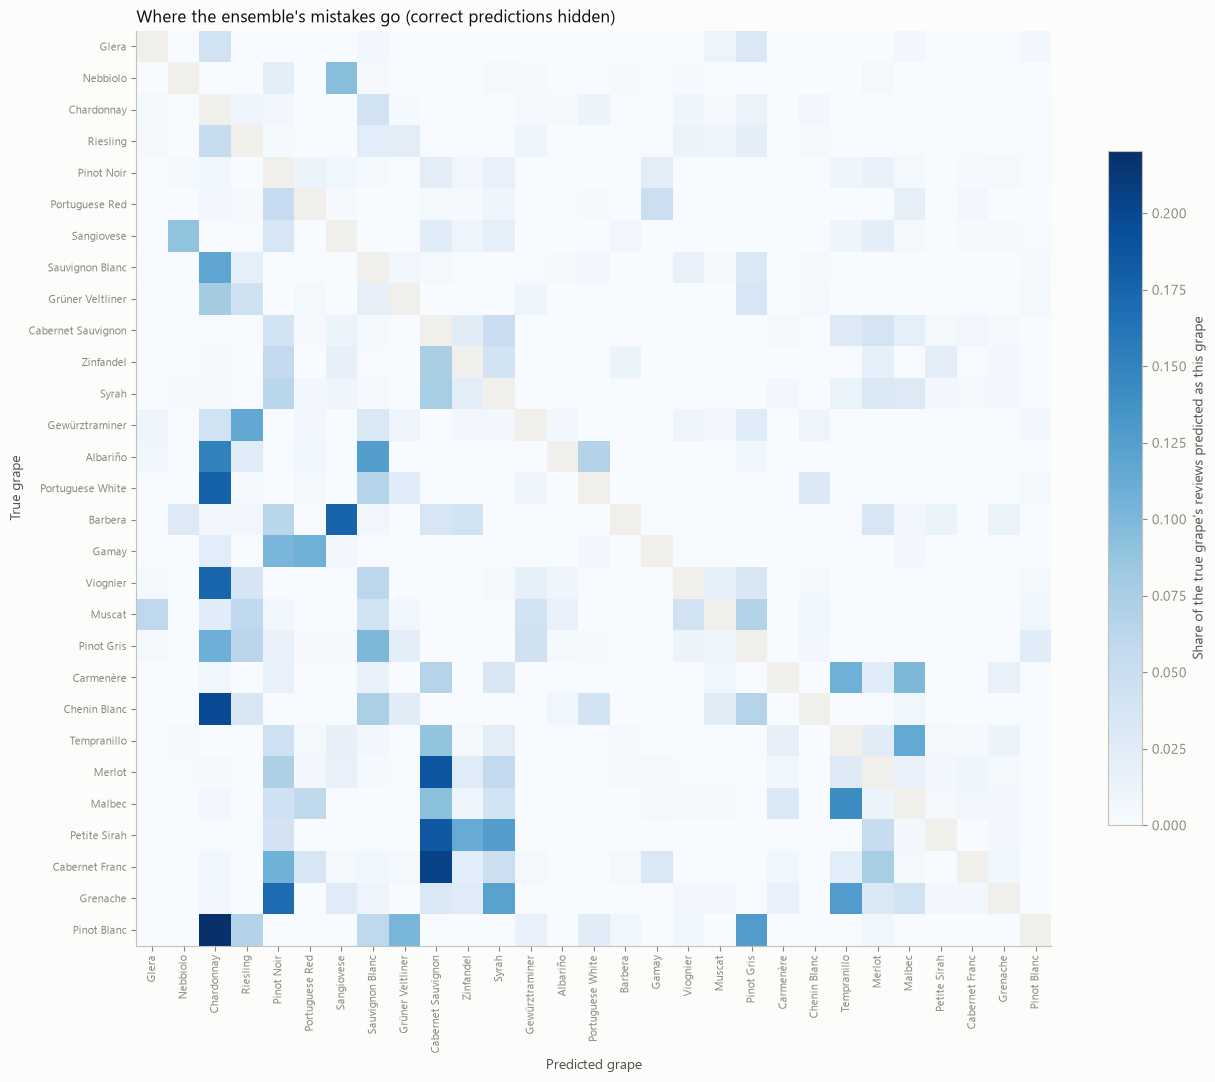

,true grape,predicted as,share
481,Pinot Blanc,Chardonnay,0.220
58,Cabernet Franc,Cabernet Sauvignon,0.203
173,Chenin Blanc,Chardonnay,0.197
367,Merlot,Cabernet Sauvignon,0.188
451,Petite Sirah,Cabernet Sauvignon,0.185
593,Portuguese White,Chardonnay,0.178
50,Barbera,Sangiovese,0.176
761,Viognier,Chardonnay,0.175
298,Grenache,Pinot Noir,0.169
4,Albariño,Chardonnay,0.151


In [74]:
pred_ens = test_probas["Ensemble: M1+M2+M3"].argmax(axis=1)
cm = confusion_matrix(y_test, pred_ens, labels=np.arange(n_classes), normalize="true")

order = [list(classes).index(g) for g in per_grape.index[::-1]]
mistakes = cm.copy()
np.fill_diagonal(mistakes, np.nan)

cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#f0efec")

with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(13, 11))
    im = ax.imshow(mistakes[np.ix_(order, order)], cmap=cmap, vmin=0)
    ax.set_xticks(range(n_classes), classes[order], rotation=90, fontsize=8)
    ax.set_yticks(range(n_classes), classes[order], fontsize=8)
    ax.set_xlabel("Predicted grape")
    ax.set_ylabel("True grape")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.7, label="Share of the true grape's reviews predicted as this grape")
    ax.set_title("Where the ensemble's mistakes go (correct predictions hidden)", loc="left", fontsize=12)
    fig.tight_layout()
    plt.show()

confused = pd.DataFrame([(classes[i], classes[j], cm[i, j]) for i in range(n_classes) for j in range(n_classes) if i != j],
                        columns=["true grape", "predicted as", "share"]).nlargest(10, "share")
display(confused.round(3))


# Bias Variance Trade off.....

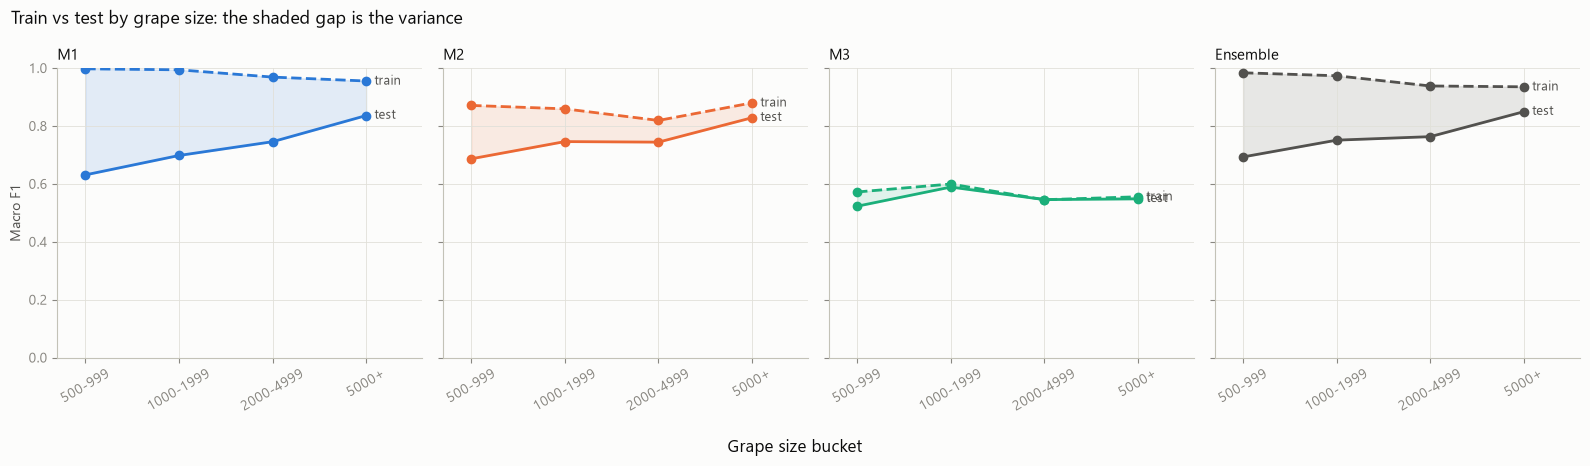

In [78]:
n = len(train)
train_probas = {
    "M1: TF-IDF + LogReg": m1.predict_proba(X_train_m1[:n]),
    "M2: Doc2Vec + BiLSTM": predict_m2(model_m2, train_ids_m2[:n], train_len_m2[:n], train_doc_m2[:n]),
    "M3: Cosine prototypes": softmax(m3_scores(train_raw) / best_T),
}
train_probas["Ensemble: M1+M2+M3"] = blend(list(train_probas.values()), best_w)

def bucket_f1(part, proba, y):
    pred = proba.argmax(axis=1)
    return [sub_f1(y, pred, (part["bucket"] == b).to_numpy()) for b in buckets]

with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, len(train_probas), figsize=(16, 4.6), sharey=True)
    for ax, name in zip(axes, train_probas):
        tr = bucket_f1(train, train_probas[name], y_train)
        te = bucket_f1(test, test_probas[name], y_test)
        ax.plot(x, tr, color=color_of(name), linestyle="--", marker="o", markersize=6)
        ax.plot(x, te, color=color_of(name), marker="o", markersize=6)
        ax.fill_between(x, te, tr, color=color_of(name), alpha=0.12)
        ax.annotate("train", (x[-1], tr[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
        ax.annotate("test", (x[-1], te[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
        ax.set_xticks(x, buckets, rotation=30)
        ax.set_xlim(-0.3, len(buckets) - 1 + 0.6)
        ax.set_title(name.split(":")[0], loc="left", fontsize=11)
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel("Macro F1")
    fig.suptitle("Train vs test by grape size: the shaded gap is the variance", x=0.01, ha="left", fontsize=13)
    fig.supxlabel("Grape size bucket")
    fig.tight_layout()
    plt.show()


# Analysis

The train-test gap is widest for grapes with 500 - 999 reviews (trainF1 for M1 vs testF1 for M1), which points out that due to high variance for rare grapes: with low amounts of reviews, our model fits their training examples closely but doesn't generalize to new reviews. For grapes with 5000 + reviews, train and test score are both high and close, meaning the model fits them well with low bias and variance. More data per grape appears to be the main lever for the rare grapes. Because the buckets contain different grapes, part of this gap may also reflect how distinctively each grape is describe. 